# The core engine outside EV charging

`core` knows nothing about vehicles. Here it models a hydrogen refuelling station: trucks
arrive, occupy one of three dispensers and are filled at a rate that falls as tank
pressure rises; a compressor limits total flow and a buffer tank covers peaks.

In [1]:
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import core

plt.style.use("paper.mplstyle")
FIGURES = Path("output/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
@dataclass(frozen=True)
class HydrogenTank:
    name: str
    capacity: float
    max_rate: float

    def max_rate_at(self, level):
        return self.max_rate if level <= 0.7 else self.max_rate * (1 - 0.8 * (level - 0.7) / 0.3)


daytime = tuple(1.0 if 6 <= hour % 24 < 22 else 0.1 for hour in range(168))


def station(arrivals_per_week, queue_capacity=4, policy="earliest_departure_first"):
    return core.System(
        network=core.NetworkSpec(
            (
                core.NodeSpec(
                    max_rate=150,
                    children=(core.ServerSpec(120),) * 3,
                    buffer=core.BufferSpec(capacity=200, max_rate=100, initial_level=1.0),
                ),
            )
        ),
        demand=core.Demand(
            arrivals=core.WeeklyProfileArrivals(
                arrivals_per_week, daytime, core.TruncatedNormal(0.75, 0.25, 0.25, 2)
            ),
            initial_level=core.TruncatedNormal(0.2, 0.1, 0, 1),
            profiles=(HydrogenTank("long-haul", 80, 120), HydrogenTank("city", 35, 60)),
            weights=(0.6, 0.4),
        ),
        operation=core.Operation(policy=policy, queue_capacity=queue_capacity),
    )


week = ("2024-05-06", "2024-05-12 23:55", "5min")
pd.DataFrame(
    {
        policy: core.simulate(station(350, policy=policy), *week, seed=1).summary()
        for policy in ["unconstrained", "earliest_departure_first", "fair_share"]
    }
).T

,requests,rejections,rejection_rate,total_quantity,peak_rate,utilisation,mean_service_hours
unconstrained,350.0,0.0,0.0,15460.354202,360.0,1.000000,0.570087
earliest_departure_first,350.0,0.0,0.0,15326.040250,250.0,0.694444,0.580684
fair_share,350.0,0.0,0.0,15206.331667,250.0,0.694444,0.578757


In [3]:
demand_levels = np.arange(100, 1101, 100)
queue_sizes = {0: "No waiting area", 4: "4 waiting places", 12: "12 waiting places"}

rejected = {
    capacity: np.array(
        [
            [
                core.simulate(station(rate, capacity), *week, seed=s).rejection_rate * 100
                for s in range(10)
            ]
            for rate in demand_levels
        ]
    )
    for capacity in queue_sizes
}

busy = core.simulate(station(700), *week, seed=1)
occupied = pd.Series((busy.rates > 0).sum(axis=1), index=busy.realisation.grid.datetime64)
by_hour = occupied.groupby(occupied.index.hour).mean()

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


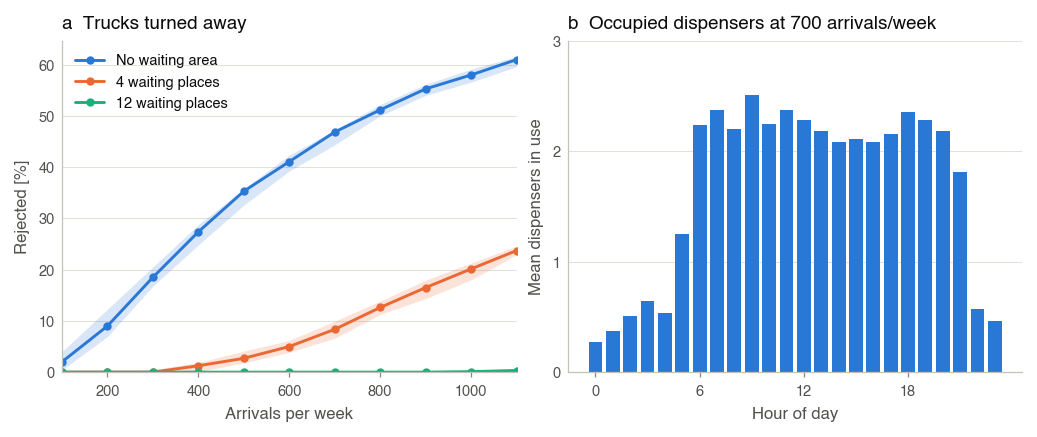

In [4]:
fig, (ax_q, ax_occ) = plt.subplots(1, 2)

for (capacity, label), color in zip(queue_sizes.items(), ["C0", "C1", "C2"], strict=True):
    low, mid, high = np.percentile(rejected[capacity], [5, 50, 95], axis=1)
    ax_q.fill_between(demand_levels, low, high, color=color, alpha=0.18, linewidth=0)
    ax_q.plot(demand_levels, mid, color=color, marker="o", markersize=3, label=label)
ax_q.set_title("a  Trucks turned away")
ax_q.set_xlabel("Arrivals per week")
ax_q.set_ylabel("Rejected [%]")
ax_q.set_xlim(demand_levels[0], demand_levels[-1])
ax_q.set_ylim(0, None)
ax_q.legend(loc="upper left")

ax_occ.bar(by_hour.index, by_hour.to_numpy(), width=0.8, color="C0")
ax_occ.set_title("b  Occupied dispensers at 700 arrivals/week")
ax_occ.set_xlabel("Hour of day")
ax_occ.set_ylabel("Mean dispensers in use")
ax_occ.set_xticks(range(0, 24, 6))
ax_occ.set_ylim(0, 3)
ax_occ.set_yticks([0, 1, 2, 3])

fig.savefig(FIGURES / "05_hydrogen.pdf")